# Network Intrusion Detection with Machine Learning (NSL-KDD)

**IBM SkillsBuild Cybersecurity Bootcamp 2026 | BharatCares | Project Submission (Deliverable 2)**

**Project idea:** ML Network Intrusion Detector. Build a Scikit-learn model that classifies network connections as normal traffic or an attack, using a public dataset.

## What this notebook does
1. Loads the public **NSL-KDD** intrusion detection dataset (the official `KDDTrain+` and `KDDTest+` files).
2. Explores the data and the four attack families (DoS, Probe, R2L, U2R).
3. Builds a preprocessing + model pipeline and compares four classifiers on the **official test set**.
4. Analyses errors, feature importance and the precision / recall trade-off that matters for a security team.
5. Trains a 5-class model that names the attack family, not just "attack".

> **Ethics note:** this project only uses a public, pre-recorded dataset. No live system, network or account is scanned or attacked. Never test a system without written authorisation.

## 1. Setup and imports

In [1]:
import time
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)


def save_fig(name):
    """Save the current figure to outputs/ (these images are reused in the report)."""
    plt.tight_layout()
    plt.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load the dataset

NSL-KDD is an improved version of the KDD Cup 1999 intrusion dataset from the Canadian Institute for Cybersecurity (University of New Brunswick). It removes duplicate records, which stops classifiers from simply memorising frequent rows.

* `KDDTrain+.txt`: 125,973 labelled connections used for training.
* `KDDTest+.txt`: 22,544 labelled connections used for testing. It contains attack types that **never appear in training**, so it is a realistic test of generalisation.

The cell below downloads the two files into `data/` the first time it runs. The files are mirrored on GitHub; the original source is <https://www.unb.ca/cic/datasets/nsl.html>.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
FILES = ["KDDTrain+.txt", "KDDTest+.txt"]

for fname in FILES:
    target = DATA_DIR / fname
    if not target.exists():
        print(f"Downloading {fname} ...")
        urllib.request.urlretrieve(BASE_URL + fname, target)
    print(f"{fname}: {target.stat().st_size / 1e6:.1f} MB")

KDDTrain+.txt: 19.1 MB
KDDTest+.txt: 3.4 MB


In [3]:
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land",
    "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty",
]

train = pd.read_csv(DATA_DIR / "KDDTrain+.txt", header=None, names=columns)
test = pd.read_csv(DATA_DIR / "KDDTest+.txt", header=None, names=columns)
print("Train:", train.shape, "| Test:", test.shape)
train.head()

Train: (125973, 43) | Test: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


### Label engineering

Each record is labelled with a specific attack name (for example `neptune`, `smurf`, `guess_passwd`) or `normal`. We group them into the standard four families and also create a binary label:

| Family | Meaning | Examples |
| --- | --- | --- |
| **DoS** | Denial of Service: flood a service so it cannot respond | neptune, smurf, back |
| **Probe** | Surveillance and scanning | satan, ipsweep, portsweep, nmap |
| **R2L** | Remote to Local: a remote attacker gains local access | guess_passwd, warezclient, ftp_write |
| **U2R** | User to Root: a normal user escalates privileges | buffer_overflow, rootkit, loadmodule |

In [4]:
ATTACK_FAMILY = {
    "normal": "Normal",
    # Denial of Service
    **{a: "DoS" for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2",
                           "udpstorm", "processtable", "worm", "mailbomb"]},
    # Probe
    **{a: "Probe" for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]},
    # Remote to Local
    **{a: "R2L" for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster",
                           "warezclient", "spy", "xlock", "xsnoop", "snmpguess", "snmpgetattack",
                           "httptunnel", "sendmail", "named"]},
    # User to Root
    **{a: "U2R" for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]},
}

for df in (train, test):
    unmapped = set(df["label"]) - set(ATTACK_FAMILY)
    assert not unmapped, f"Unmapped labels: {unmapped}"
    df["family"] = df["label"].map(ATTACK_FAMILY)
    df["is_attack"] = (df["label"] != "normal").astype(int)

print("Distinct attack names -> train:", train["label"].nunique() - 1, "| test:", test["label"].nunique() - 1)
unseen = sorted(set(test["label"]) - set(train["label"]))
print(f"Attack types present ONLY in the test set ({len(unseen)}): {unseen}")

Distinct attack names -> train: 22 | test: 37
Attack types present ONLY in the test set (17): ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


## 3. Exploratory data analysis

In [5]:
print("Missing values  -> train:", int(train.isna().sum().sum()), "| test:", int(test.isna().sum().sum()))
print("Duplicate rows  -> train:", int(train.duplicated().sum()), "| test:", int(test.duplicated().sum()))

summary = pd.DataFrame({
    "train_count": train["family"].value_counts(),
    "train_%": (train["family"].value_counts(normalize=True) * 100).round(2),
    "test_count": test["family"].value_counts(),
    "test_%": (test["family"].value_counts(normalize=True) * 100).round(2),
}).loc[["Normal", "DoS", "Probe", "R2L", "U2R"]]
summary

Missing values  -> train: 0 | test: 0
Duplicate rows  -> train: 0 | test: 0


,train_count,train_%,test_count,test_%
family,,,,
Normal,67343,53.46,9711,43.08
DoS,45927,36.46,7460,33.09
Probe,11656,9.25,2421,10.74
R2L,995,0.79,2885,12.80
U2R,52,0.04,67,0.30


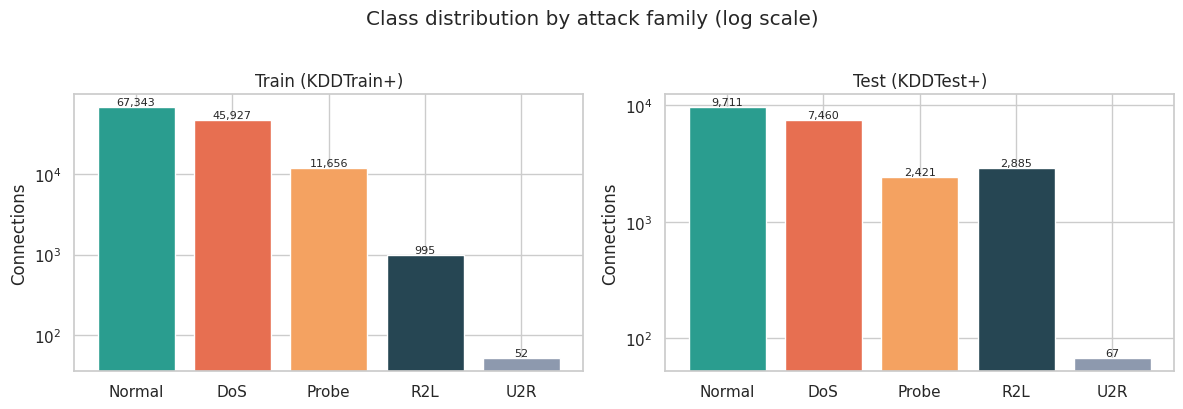

In [6]:
order = ["Normal", "DoS", "Probe", "R2L", "U2R"]
palette = {"Normal": "#2a9d8f", "DoS": "#e76f51", "Probe": "#f4a261", "R2L": "#264653", "U2R": "#8d99ae"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, df) in zip(axes, [("Train (KDDTrain+)", train), ("Test (KDDTest+)", test)]):
    counts = df["family"].value_counts().reindex(order)
    ax.bar(counts.index, counts.values, color=[palette[k] for k in counts.index])
    ax.set_title(name)
    ax.set_ylabel("Connections")
    ax.set_yscale("log")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
fig.suptitle("Class distribution by attack family (log scale)", y=1.02)
save_fig("01_class_distribution.png")

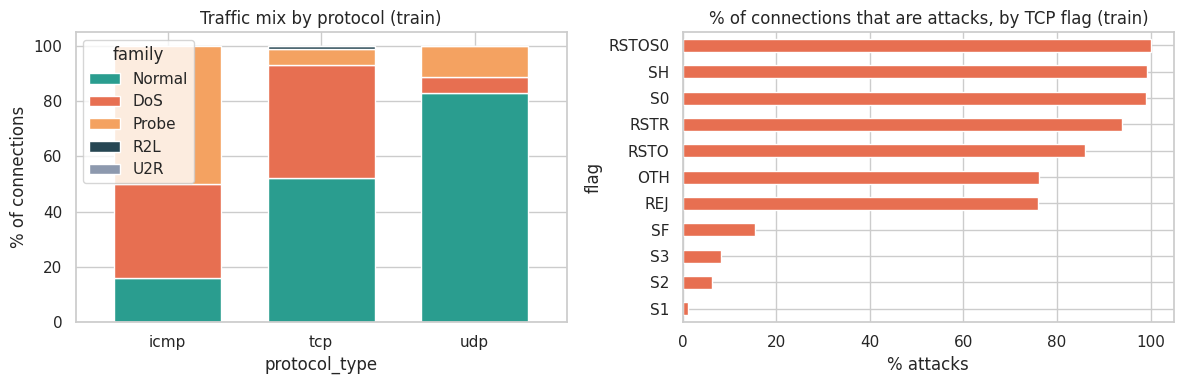

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

proto = pd.crosstab(train["protocol_type"], train["family"], normalize="index")[order] * 100
proto.plot(kind="bar", stacked=True, ax=axes[0], color=[palette[k] for k in order], width=0.7)
axes[0].set_title("Traffic mix by protocol (train)")
axes[0].set_ylabel("% of connections")
axes[0].tick_params(axis="x", rotation=0)

flag = pd.crosstab(train["flag"], train["is_attack"], normalize="index")[1] * 100
flag.sort_values().plot(kind="barh", ax=axes[1], color="#e76f51")
axes[1].set_title("% of connections that are attacks, by TCP flag (train)")
axes[1].set_xlabel("% attacks")
save_fig("02_protocol_and_flag.png")

**Reading the plots.** The dataset is dominated by Normal and DoS traffic, while R2L and especially U2R are rare. Rare classes are exactly where real intrusion detectors struggle, so we will track recall per family and not only overall accuracy. The TCP `flag` column is very informative: `S0` and `REJ` (connection attempts that never complete) are typical of floods and scans.

## 4. Preprocessing pipeline

* **Categorical** columns (`protocol_type`, `service`, `flag`) are one-hot encoded. `handle_unknown="ignore"` matters because the test set contains services that never appear in training.
* **Numeric** columns are standardised, which helps the linear model.
* `difficulty` is dropped because it is a dataset annotation, not a network feature, and `num_outbound_cmds` is dropped because it is constant (always 0).
* Everything lives inside one scikit-learn `Pipeline`, so the preprocessing is learned from the training data only (no data leakage).

In [8]:
DROP_COLS = ["label", "family", "is_attack", "difficulty", "num_outbound_cmds"]
CATEGORICAL = ["protocol_type", "service", "flag"]

X_train = train.drop(columns=DROP_COLS)
X_test = test.drop(columns=DROP_COLS)
y_train, y_test = train["is_attack"], test["is_attack"]
NUMERIC = [c for c in X_train.columns if c not in CATEGORICAL]


def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])


print(f"{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical input columns")
print("Train attack rate: %.1f%% | Test attack rate: %.1f%%" % (y_train.mean() * 100, y_test.mean() * 100))

37 numeric + 3 categorical input columns
Train attack rate: 46.5% | Test attack rate: 56.9%


## 5. Binary detection: normal vs attack

We compare four classifiers, from a simple interpretable baseline to stronger tree ensembles. All are trained on `KDDTrain+` and judged on the untouched `KDDTest+`.

For intrusion detection the two kinds of mistake have very different costs:

* **False negative (missed attack):** the intruder gets in unnoticed. This is the costly error, so **recall** matters most.
* **False positive (false alarm):** an analyst wastes time. Too many cause alert fatigue, so **precision** matters too.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

fitted, probas, rows = {}, {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_s = time.time() - t0
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fitted[name], probas[name] = pipe, proba
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Train time (s)": fit_s,
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results.to_csv(OUT_DIR / "model_results.csv")
results.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC,Train time (s)
Model,,,,,,
Decision Tree,0.8103,0.9662,0.6910,0.8057,0.8297,10.5497
Hist Gradient Boosting,0.8082,0.9696,0.6845,0.8025,0.9602,14.7927
Random Forest,0.7703,0.9680,0.6168,0.7535,0.9623,41.0427
Logistic Regression,0.7540,0.9175,0.6240,0.7428,0.7916,19.2726


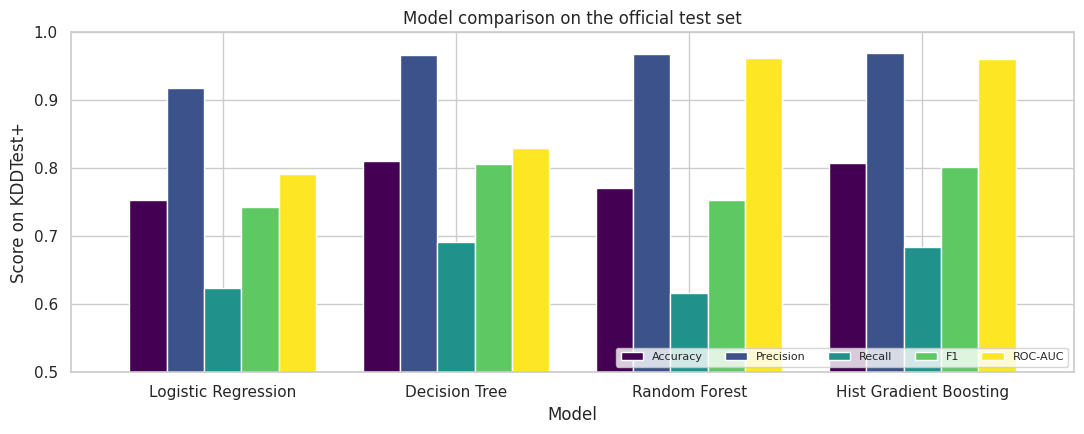

Best model by F1: Decision Tree


In [10]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
ax = results[metrics].plot(kind="bar", figsize=(11, 4.5), width=0.8, colormap="viridis")
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("Score on KDDTest+")
ax.set_title("Model comparison on the official test set")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right", ncol=5, fontsize=8)
save_fig("03_model_comparison.png")

best_name = results["F1"].idxmax()
print("Best model by F1:", best_name)

### Does the model generalise? Cross-validation vs the official test set

Cross-validation on the training data mixes records from the same attack types, so it tends to look excellent. The official test set contains new attack types, so scores drop. The gap is the honest picture of how an IDS behaves against attacks it has not seen before.

In [11]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
rf_cv_pipe = Pipeline([("prep", make_preprocessor()),
                       ("clf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE))])
cv_f1 = cross_val_score(rf_cv_pipe, X_train, y_train, cv=cv, scoring="f1")
test_f1 = results.loc["Random Forest", "F1"]

gap = pd.DataFrame({"Random Forest F1": [cv_f1.mean(), test_f1]},
                   index=["3-fold CV on KDDTrain+", "Official test set (KDDTest+)"]).round(4)
print(gap)

                              Random Forest F1
3-fold CV on KDDTrain+                  0.9987
Official test set (KDDTest+)            0.7535


### Error analysis for the best model

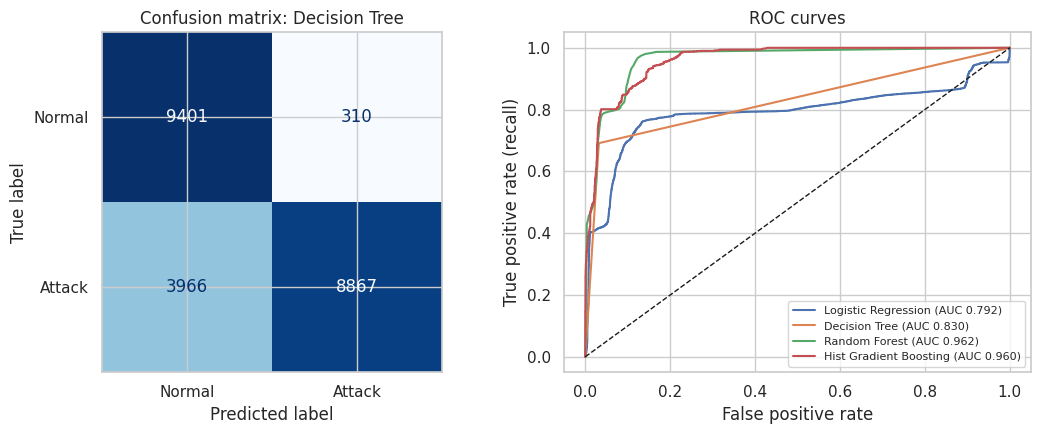

Caught attacks: 8,867 | Missed attacks: 3,966 | False alarms: 310 | Correct normals: 9,401


In [12]:
best = fitted[best_name]
best_pred = best.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["Normal", "Attack"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix: {best_name}")
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curves")
axes[1].legend(fontsize=8, loc="lower right")
save_fig("04_confusion_and_roc.png")

tn, fp, fn, tp = confusion_matrix(y_test, best_pred).ravel()
print(f"Caught attacks: {tp:,} | Missed attacks: {fn:,} | False alarms: {fp:,} | Correct normals: {tn:,}")

**Which attacks are slipping through?** The table shows the detection rate for each attack family using the best model. Families with low detection are the ones an analyst should worry about.

In [13]:
eval_df = test[["family"]].copy()
eval_df["detected"] = best_pred
per_family = (eval_df.groupby("family")["detected"].agg(connections="size", detected="sum"))
per_family["detection_rate_%"] = (
    per_family.apply(lambda r: r["detected"] / r["connections"] * 100, axis=1)).round(1)
# For Normal traffic, "detected" means a false alarm.
per_family = per_family.rename(index={"Normal": "Normal (false-alarm rate)"})
per_family.loc[["Normal (false-alarm rate)", "DoS", "Probe", "R2L", "U2R"]]

,connections,detected,detection_rate_%
family,,,
Normal (false-alarm rate),9711,310,3.2
DoS,7460,6171,82.7
Probe,2421,1952,80.6
R2L,2885,725,25.1
U2R,67,19,28.4


### Which features drive the decisions?

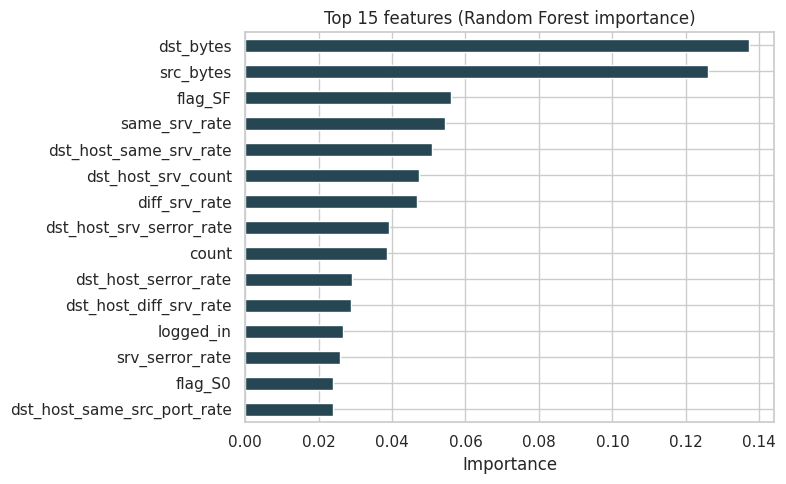

,importance
dst_bytes,0.1371
src_bytes,0.1260
flag_SF,0.0560
same_srv_rate,0.0545
dst_host_same_srv_rate,0.0508
dst_host_srv_count,0.0474
diff_srv_rate,0.0469
dst_host_srv_serror_rate,0.0393
count,0.0387
dst_host_serror_rate,0.0291


In [14]:
rf = fitted["Random Forest"]
feat_names = rf.named_steps["prep"].get_feature_names_out()
imp = (pd.Series(rf.named_steps["clf"].feature_importances_, index=feat_names)
       .sort_values(ascending=False).head(15))
imp.index = [i.replace("num__", "").replace("cat__", "") for i in imp.index]

ax = imp.iloc[::-1].plot(kind="barh", figsize=(8, 5), color="#264653")
ax.set_title("Top 15 features (Random Forest importance)")
ax.set_xlabel("Importance")
save_fig("05_feature_importance.png")
imp.round(4).to_frame("importance")

### Precision vs recall: choosing an alert threshold

A model outputs a probability; the **threshold** decides when to raise an alert. Lowering it catches more attacks (higher recall) but creates more false alarms (lower precision). This analysis uses the test set only to *illustrate* the trade-off. In a real deployment the threshold must be chosen on separate validation data, never on the test set.

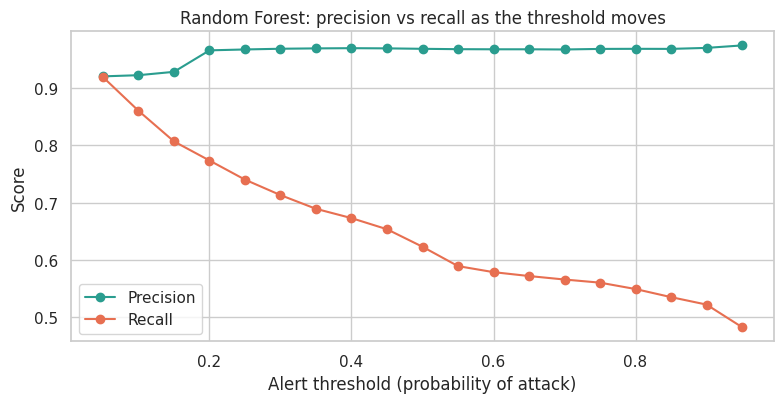

,threshold,precision,recall,false_alarms
0,0.15,0.928,0.807,803
1,0.25,0.967,0.740,324
2,0.50,0.968,0.623,263
3,0.75,0.968,0.560,238
4,0.85,0.968,0.535,227


In [15]:
thr = np.linspace(0.05, 0.95, 19)
p = probas["Random Forest"]
sweep = pd.DataFrame({
    "threshold": thr,
    "precision": [precision_score(y_test, p >= t) for t in thr],
    "recall": [recall_score(y_test, p >= t) for t in thr],
    "false_alarms": [int(((p >= t) & (y_test == 0)).sum()) for t in thr],
})

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sweep["threshold"], sweep["precision"], marker="o", label="Precision", color="#2a9d8f")
ax.plot(sweep["threshold"], sweep["recall"], marker="o", label="Recall", color="#e76f51")
ax.set_xlabel("Alert threshold (probability of attack)")
ax.set_ylabel("Score")
ax.set_title("Random Forest: precision vs recall as the threshold moves")
ax.legend()
save_fig("06_threshold_tradeoff.png")
sweep.iloc[[2, 4, 9, 14, 16]].round(3).reset_index(drop=True)

## 6. Multi-class detection: naming the attack family

Knowing the *type* of attack tells the analyst how to respond (block a flood, investigate a scan, reset credentials). We train a Random Forest on the five classes. Balanced class weights stop the rare R2L and U2R classes from being ignored.

In [16]:
fam_model = Pipeline([
    ("prep", make_preprocessor()),
    ("clf", RandomForestClassifier(n_estimators=200, n_jobs=-1, class_weight="balanced_subsample",
                                   random_state=RANDOM_STATE)),
])
fam_model.fit(X_train, train["family"])
fam_pred = fam_model.predict(X_test)

print(classification_report(test["family"], fam_pred, labels=order, digits=3))
report = pd.DataFrame(classification_report(test["family"], fam_pred, labels=order,
                                            output_dict=True)).T.round(3)
report.to_csv(OUT_DIR / "multiclass_report.csv")

              precision    recall  f1-score   support

      Normal      0.634     0.974     0.768      9711
         DoS      0.961     0.765     0.852      7460
       Probe      0.863     0.593     0.703      2421
         R2L      0.810     0.006     0.012      2885
         U2R      0.500     0.030     0.056        67

    accuracy                          0.737     22544
   macro avg      0.754     0.473     0.478     22544
weighted avg      0.789     0.737     0.690     22544



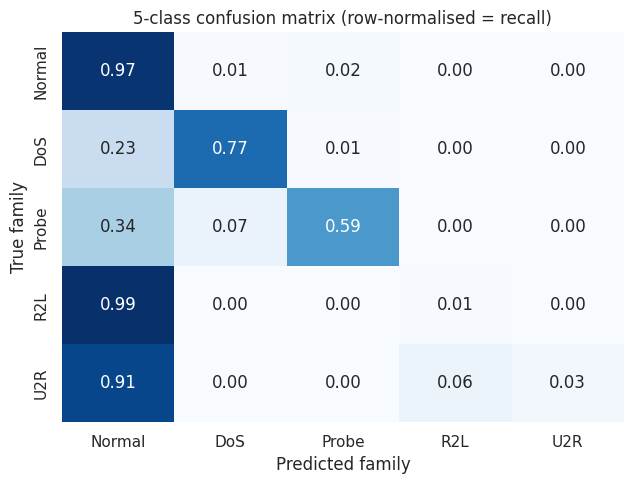

In [17]:
cm = confusion_matrix(test["family"], fam_pred, labels=order, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=order, yticklabels=order, ax=ax,
            cbar=False)
ax.set_xlabel("Predicted family")
ax.set_ylabel("True family")
ax.set_title("5-class confusion matrix (row-normalised = recall)")
save_fig("07_multiclass_confusion.png")

## 7. Results summary

In [18]:
best_row = results.loc[best_name]
fam_rec = recall_score(test["family"], fam_pred, labels=order, average=None)
print("=" * 62)
print("SUMMARY (official test set, KDDTest+)")
print("=" * 62)
print(f"Best binary model        : {best_name}")
print(f"  Accuracy / F1 / AUC    : {best_row['Accuracy']:.3f} / {best_row['F1']:.3f} / {best_row['ROC-AUC']:.3f}")
print(f"  Precision / Recall     : {best_row['Precision']:.3f} / {best_row['Recall']:.3f}")
print(f"Random Forest CV F1 (train): {cv_f1.mean():.3f}  vs  test F1: {test_f1:.3f}")
print("5-class recall by family  : " + ", ".join(f"{f} {r:.2f}" for f, r in zip(order, fam_rec)))
print("Figures and tables saved in:", OUT_DIR.resolve())

SUMMARY (official test set, KDDTest+)
Best binary model        : Decision Tree
  Accuracy / F1 / AUC    : 0.810 / 0.806 / 0.830
  Precision / Recall     : 0.966 / 0.691
Random Forest CV F1 (train): 0.999  vs  test F1: 0.753
5-class recall by family  : Normal 0.97, DoS 0.77, Probe 0.59, R2L 0.01, U2R 0.03
Figures and tables saved in: /content/outputs


## 8. Conclusions and limitations

**Key results** (official `KDDTest+` set, `random_state=42`; exact digits can vary slightly with library versions):

* **Best binary model by F1: Decision Tree** with 81.0% accuracy, 96.6% precision, 69.1% recall and F1 0.806. Hist Gradient Boosting is almost identical (F1 0.804). Random Forest and Hist Gradient Boosting have the best ROC-AUC (0.962 and 0.959 against 0.830 for the tree), which means they rank connections better and are the stronger choice when the alert threshold can be tuned.
* **Seen vs unseen attacks:** Random Forest scores F1 0.999 in cross-validation on the training data but 0.754 on the test set. 17 of the 37 attack types in the test set never appear in training, and that gap is the main finding of this project.
* **False alarms are low, missed attacks are not:** the best model flags only 3.2% of normal connections (310 of 9,711) but misses 3,966 of 12,833 attacks.
* **Detection differs by family:** DoS (82.7%) and Probe (80.6%) are caught well. R2L (25.1%) and U2R (28.4%) are mostly missed. In the 5-class model R2L recall falls to 0.3% and U2R to 4.5%.
* **Threshold matters:** for the Random Forest, lowering the alert threshold from 0.50 to 0.15 raises recall from 62.3% to 80.7%, while false alarms rise from 263 to 803 and precision falls from 96.8% to 92.8%.
* **Most influential features:** `dst_bytes`, `src_bytes`, the `SF` TCP flag, `same_srv_rate` and `dst_host_same_srv_rate`, which describe how much data moved and how a connection ended.

**Limitations**

* R2L and U2R are rare in the training data (995 and 52 records), and many R2L test attacks are new types, so the model has little to learn from.
* NSL-KDD is a 1999-era simulated dataset with pre-computed connection features. It does not represent modern encrypted traffic, so results show the method, not production performance.
* The evaluation is offline, with a single random seed and no extensive hyper-parameter tuning.

**Future work:** add anomaly-detection models (for example Isolation Forest) to catch unseen attacks, rebalance the rare classes, tune thresholds on a validation split, and test on newer datasets such as CIC-IDS2017 or UNSW-NB15.

## 9. References

* Tavallaee, M., Bagheri, E., Lu, W., Ghorbani, A. (2009). *A Detailed Analysis of the KDD CUP 99 Data Set.* IEEE CISDA. Dataset: <https://www.unb.ca/cic/datasets/nsl.html>
* scikit-learn documentation: <https://scikit-learn.org/stable/>
* IBM SkillsBuild Cybersecurity Bootcamp 2026 (BharatCares) masterclass material on attack life cycle, SOC metrics and ethical hacking.